# 01 · Catalogues

Anna Preto — AstroDeep Project

The demo box catalogue, the blending entropy S_b, cuts 1 and 2, and three checks on copaings: Euclid angle convention, S_b = 0 outside one-to-one groups, Rubin cut on `i_extendedness`.

Reads the products of the local pipeline (`dp2-cutouts config/local_demo.yaml all`). The outputs of this notebook show Rubin DP2 pixels: **never commit them** (clear the outputs before committing).

In [2]:
from pathlib import Path
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dp2_cutouts.config import Config
from dp2_cutouts import viz

CONFIG = Path("../config/local_demo.yaml")
cfg = Config.load(CONFIG)
cc = cfg["cuts"]
table = pd.read_parquet(cfg.data("tables_and_stamps", "table.parquet"))
plt.rcParams["figure.dpi"] = 110
print(f"{len(table):,} objects in the catalogue")

14,044 objects in the catalogue


## Blending entropy

`S_b = -1`: no overlap; `0`: a single candidate; `> 0`: blend.

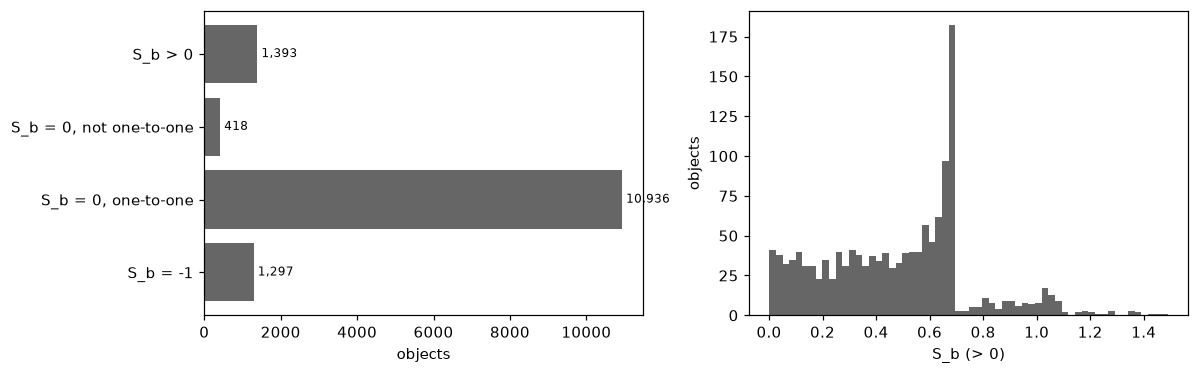

In [3]:
s = table["sb_euclid"]
cats = {"S_b = -1": (s == -1).sum(), "S_b = 0, one-to-one": table["cut2_pass"].sum(),
        "S_b = 0, not one-to-one": ((s == 0) & ~table["cut2_pass"]).sum(), "S_b > 0": (s > 0).sum()}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].barh(list(cats), list(cats.values()), color="0.4")
for i, v in enumerate(cats.values()):
    axes[0].text(v, i, f" {v:,}", va="center", fontsize=8)
axes[0].set_xlabel("objects")
axes[1].hist(s[s > 0], bins=60, color="0.4")
axes[1].set_xlabel("S_b (> 0)"); axes[1].set_ylabel("objects")
plt.tight_layout()

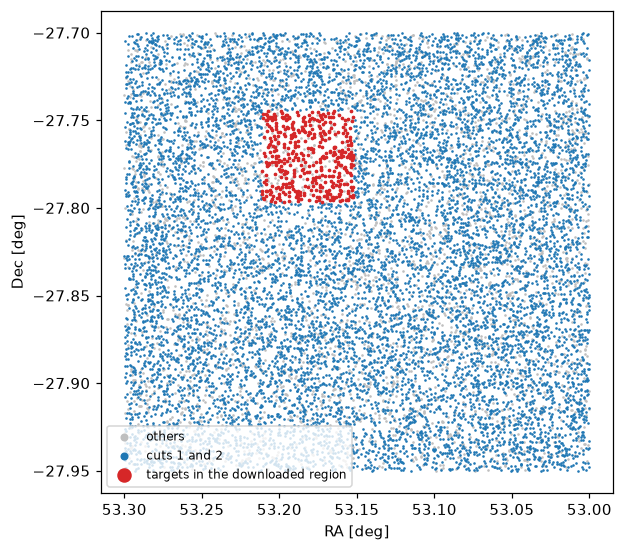

In [4]:
meta = json.load(open(cfg.data("rubin_data", "images", "images.json")))
fig, ax = plt.subplots(figsize=(6, 6))
ok = table["cut1_pass"] & table["cut2_pass"]
ax.scatter(table.loc[~ok, "ra"], table.loc[~ok, "dec"], s=0.5, c="0.75", label="others")
ax.scatter(table.loc[ok, "ra"], table.loc[ok, "dec"], s=0.5, c="C0", label="cuts 1 and 2")
reg = table[table["in_region"]]
ax.scatter(reg["ra"], reg["dec"], s=2, c="C3", label="targets in the downloaded region")
ax.invert_xaxis(); ax.set_xlabel("RA [deg]"); ax.set_ylabel("Dec [deg]"); ax.set_aspect(1 / np.cos(np.radians(-27.8)))
ax.legend(markerscale=6, fontsize=8, loc="lower left")

## Cut 1: Euclid flags of the counterpart

`point_like_flag` is almost always empty in Q1; the cut then relies on `spurious_flag`. The `point_like_prob` probability is recorded.

point_like_flag: {<NA>: 10934, np.int64(1): 2}
spurious_flag:   {np.int64(0): 10917, np.int64(1): 19}


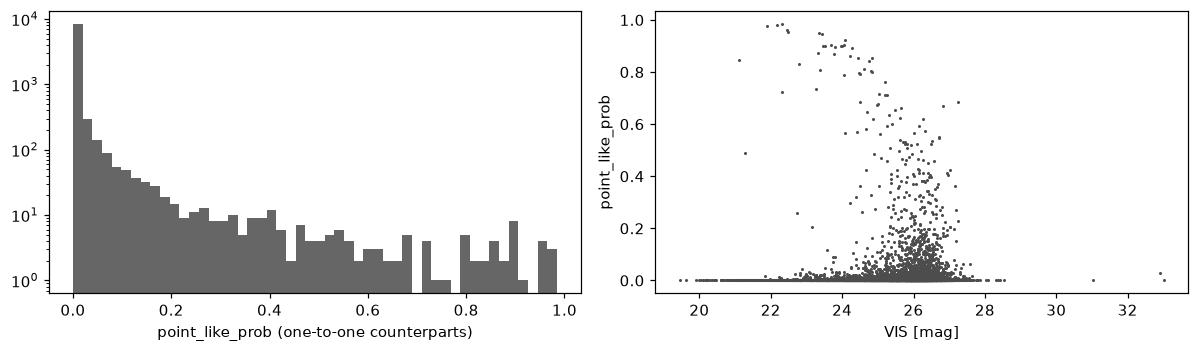

In [5]:
c = table[table["has_euclid_counterpart"]]
print("point_like_flag:", c["euclid_point_like_flag"].value_counts(dropna=False).to_dict())
print("spurious_flag:  ", c["euclid_spurious_flag"].value_counts(dropna=False).to_dict())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].hist(c["euclid_point_like_prob"].dropna(), bins=50, color="0.4", log=True)
axes[0].set_xlabel("point_like_prob (one-to-one counterparts)")
axes[1].scatter(c["euclid_vis_mag"], c["euclid_point_like_prob"], s=1, c="0.3")
axes[1].set_xlabel("VIS [mag]"); axes[1].set_ylabel("point_like_prob")
plt.tight_layout()

## Check 1: angle convention of the Euclid ellipses in copaings

In the Rubin pixel frame, copaings uses θ = 270 − (PA + 90) = −PA. On elongated one-to-one pairs, the angle of the Rubin moments follows θ = PA + 90.

385 pairs


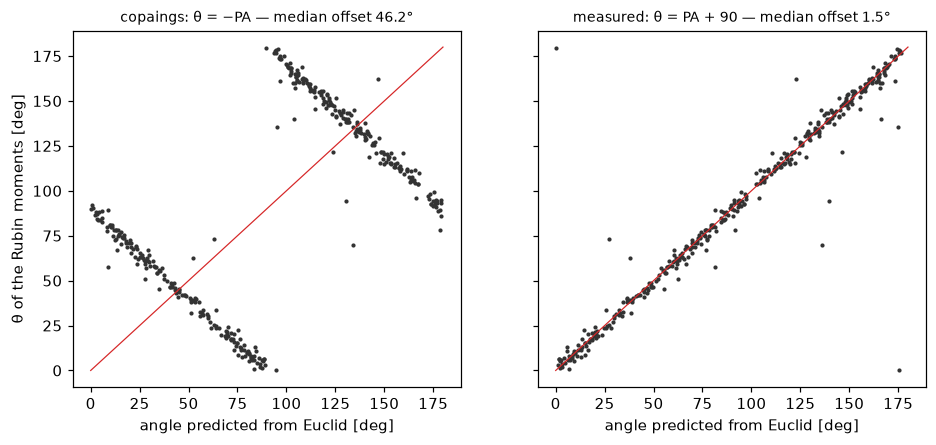

In [6]:
p = table[table["has_euclid_counterpart"] & (table["euclid_ellipticity"] > 0.3)
          & (np.hypot(table["e1_moments"], table["e2_moments"]) > 0.3) & (table["i_cModel_mag"] < 23)]
pa = p["euclid_position_angle"] - 90  # raw PA from the MER catalogue
th = p["ellipse_theta"]
wrap = lambda d: (d + 90) % 180 - 90
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, cand, name in [(axes[0], -pa, "copaings: θ = −PA"), (axes[1], pa + 90, "measured: θ = PA + 90")]:
    ax.scatter(cand % 180, th, s=3, c="0.2")
    ax.plot([0, 180], [0, 180], c="C3", lw=0.8)
    ax.set_title(f"{name} — median offset {np.median(np.abs(wrap(th - cand))):.1f}°", fontsize=9)
    ax.set_xlabel("angle predicted from Euclid [deg]")
axes[0].set_ylabel("θ of the Rubin moments [deg]")
print(f"{len(p)} pairs")

In [7]:
alt = Path(str(cfg.data_root) + "_measured") / "tables_and_stamps" / "catalog.parquet"
if alt.exists():
    b = pd.read_parquet(alt).set_index("object_id")
    a = table.set_index("object_id")
    sa, sb = set(a.index[a["cut2_pass"]]), set(b.index[b["cut2_pass"]])
    print(f"cut 2 — copaings convention: {len(sa):,}; measured convention: {len(sb):,}; "
          f"lost {len(sa - sb)}, gained {len(sb - sa)}")
else:
    print("variant not computed (config/local_demo_measured.yaml)")

variant not computed (config/local_demo_measured.yaml)


## Check 2: S_b = 0 outside one-to-one groups

In [8]:
cdir = cfg.data("copaings_matching", cfg.name, "x").parent
groups = pickle.load(open(cdir / "groups" / "E_no_overlap.pkl", "rb"))["data"]
shape = {}
for g in groups:
    for o in g[1]:
        shape[o] = f"{len(g[0])} Euclid / {len(g[1])} Rubin"
odd = table.index[(table["sb_euclid"] == 0) & ~table["has_euclid_counterpart"]]
print(f"{len(odd)} objects with S_b = 0 outside one-to-one groups; group composition:")
pd.Series([shape.get(i, "none") for i in odd]).value_counts().head(8)

418 objects with S_b = 0 outside one-to-one groups; group composition:


1 Euclid / 2 Rubin    139
2 Euclid / 2 Rubin    120
2 Euclid / 1 Rubin     73
2 Euclid / 3 Rubin     26
3 Euclid / 2 Rubin     25
3 Euclid / 1 Rubin      9
3 Euclid / 3 Rubin      7
3 Euclid / 4 Rubin      4
Name: count, dtype: int64

## Check 3: the copaings `i_extendedness == 1` cut

The copaings `prep` step removes point-like Rubin objects and those without a value before the overlap test: they no longer count as neighbours. How many kept targets have such an object very close by?

In [9]:
from astropy.coordinates import SkyCoord
import astropy.units as u
raw = pd.read_parquet(cfg.data("rubin_data", "catalog", "object_box.parquet"))
r0, r1, d0, d1 = cfg.sky_box
raw = raw[raw["coord_ra"].between(r0, r1) & raw["coord_dec"].between(d0, d1)]
dropped = raw[raw["i_extendedness"] != 1]
print(f"Rubin objects removed by prep: {len(dropped):,} (point-like {int((raw['i_extendedness'] == 0).sum()):,}, "
      f"no value {int(raw['i_extendedness'].isna().sum()):,})")
tg = table[table["cut1_pass"] & table["cut2_pass"]]
c1 = SkyCoord(tg["ra"].values * u.deg, tg["dec"].values * u.deg)
c2 = SkyCoord(dropped["coord_ra"].values * u.deg, dropped["coord_dec"].values * u.deg)
for r in (1.0, 2.0, 3.0):
    i1, _, _, _ = c2.search_around_sky(c1, r * u.arcsec)
    n = len(np.unique(i1))
    print(f"targets (1 and 2) with a removed object within {r:.0f}\": {n:,} / {len(tg):,} ({n / len(tg):.1%})")

Rubin objects removed by prep: 7,331 (point-like 3,262, no value 4,069)
targets (1 and 2) with a removed object within 1": 8 / 10,916 (0.1%)
targets (1 and 2) with a removed object within 2": 660 / 10,916 (6.0%)
targets (1 and 2) with a removed object within 3": 1,928 / 10,916 (17.7%)


## Photometric redshift of the targets (recorded, never cut on)

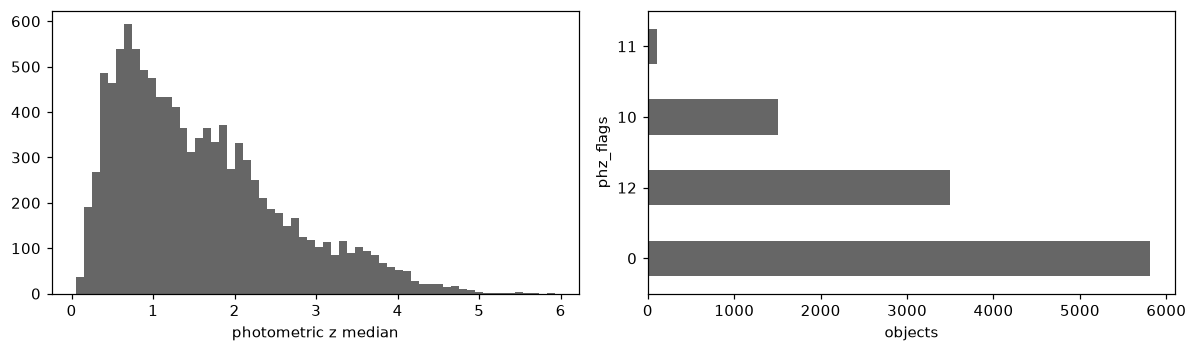

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].hist(tg["euclid_phz_median"].dropna(), bins=60, color="0.4")
axes[0].set_xlabel("photometric z median")
tg["euclid_phz_flags"].value_counts(dropna=False).head(10).plot.barh(ax=axes[1], color="0.4")
axes[1].set_xlabel("objects"); axes[1].set_ylabel("phz_flags")
plt.tight_layout()